In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Niveaux de batterie du bus 1 (depot_04), E[1,0] ... E[1,48]
energie = [
    450.0, 450.0, 450.0, 450.0, 425.0, 400.0, 375.0, 350.0, 325.0, 300.0,
    300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0,
    300.0, 315.0, 315.0, 290.0, 265.0, 240.0, 215.0, 190.0, 165.0, 140.0,
    115.0, 90.0, 90.0, 90.0, 90.0, 165.0, 165.0, 165.0, 165.0, 240.0,
    240.0, 315.0, 365.0, 365.0, 365.0, 365.0, 365.0, 385.0, 450.0,
]

reserve = 90.0
capacity = 450.0

# Échelle continue en heures depuis 04:00 (période 0 → 4.0, période 48 → 28.0)
# pour éviter la rupture à minuit (24 → 0).
heures = [4.0 + 0.5 * t for t in range(len(energie))]

def format_heure(h):
    """Convertit 4.0..28.0 en étiquette HH:MM (mod 24)."""
    h24 = h % 24
    hh = int(h24)
    mm = int(round((h24 - hh) * 60))
    if mm == 60:
        hh = (hh + 1) % 24
        mm = 0
    return f"{hh:02d}:{mm:02d}"

df = pd.DataFrame({
    "heure": heures,
    "batterie (kWh)": energie,
})

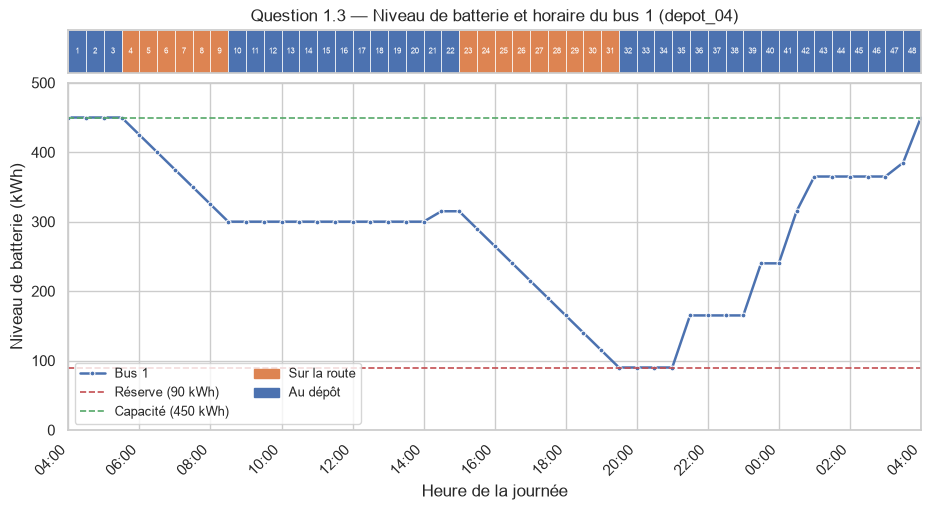

In [26]:
sns.set_theme(style="whitegrid")
from matplotlib.patches import Patch

away_bus1 = [0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

fig, (ax_h, ax) = plt.subplots(
    2, 1, figsize=(11, 5.2), sharex=True,
    gridspec_kw={"height_ratios": [1, 8], "hspace": 0.05},
)

# Bande de l'horaire : une case par période (numéro de période dans la case)
for t, a in enumerate(away_bus1, start=1):
    debut = 4.0 + 0.5 * (t - 1)
    ax_h.barh(0, 0.5, left=debut, height=1, color="C1" if a else "C0",
              edgecolor="white", linewidth=0.5)
    ax_h.text(debut + 0.25, 0, str(t), ha="center", va="center", fontsize=6, color="white")
ax_h.set_yticks([])
ax_h.set_ylim(-0.5, 0.5)
ax_h.grid(False)
ax_h.set_title("Question 1.3 — Niveau de batterie et horaire du bus 1 (depot_04)")

sns.lineplot(
    data=df,
    x="heure",
    y="batterie (kWh)",
    marker="o",
    markersize=3.5,
    linewidth=1.8,
    ax=ax,
    label="Bus 1",
)

ax.axhline(reserve, color="C3", linestyle="--", linewidth=1.2, label=f"Réserve ({reserve:.0f} kWh)")
ax.axhline(capacity, color="C2", linestyle="--", linewidth=1.2, label=f"Capacité ({capacity:.0f} kWh)")

# Ticks toutes les 2 h, de 04:00 à 04:00 le lendemain
ticks = list(range(4, 29, 2))  # 4, 6, ..., 28
ax.set_xticks(ticks)
ax.set_xticklabels([format_heure(h) for h in ticks], rotation=45, ha="right")
ax.set_xlim(4, 28)
ax.set_ylim(0, 500)

ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Niveau de batterie (kWh)")
handles, labels = ax.get_legend_handles_labels()
handles += [Patch(color="C1", label="Sur la route"), Patch(color="C0", label="Au dépôt")]
ax.legend(handles=handles, loc="lower left", ncol=2, fontsize=9)

plt.savefig("Q1/1_3_batterie_bus1.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
# Question 1.4 
puissance = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 30.0, 150.0, 0.0, 30.0, 30.0, 0.0, 60.0, 0.0, 0.0, 0.0, 150.0, 30.0, 30.0, 150.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 270.0, 90.0, 600.0, 300.0, 300.0, 330.0, 600.0, 600.0, 600.0, 600.0, 600.0, 600.0, 600.0, 600.0, 600.0, 600.0]
grid_limit = 600.0

# Début de chaque période : t=1 → 04:00, t=48 → 03:30
heures_p = [4.0 + 0.5 * (t - 1) for t in range(1, len(puissance) + 1)]

df_p = pd.DataFrame({
    "heure": heures_p,
    "puissance (kW)": puissance,
})

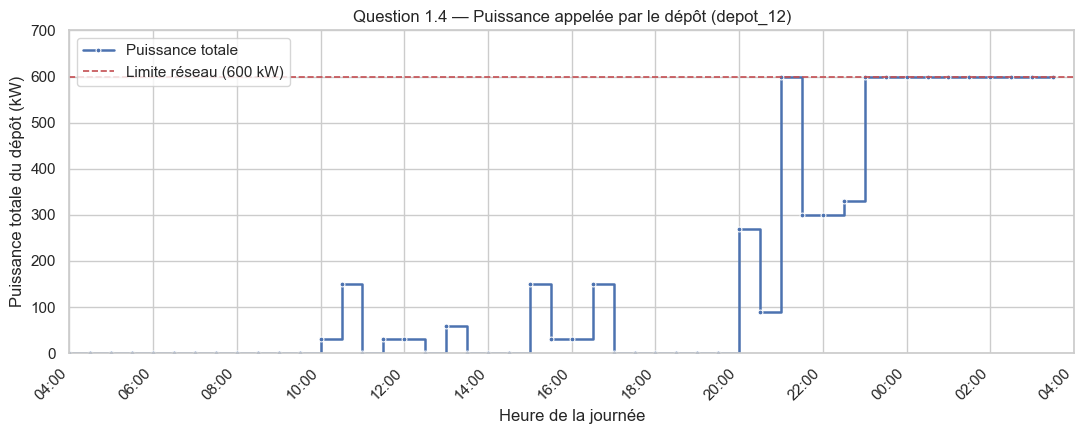

In [5]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 4.5))

sns.lineplot(
    data=df_p,
    x="heure",
    y="puissance (kW)",
    marker="o",
    markersize=3.5,
    linewidth=1.8,
    ax=ax,
    label="Puissance totale",
    drawstyle="steps-post",
)

ax.axhline(
    grid_limit,
    color="C3",
    linestyle="--",
    linewidth=1.2,
    label=f"Limite réseau ({grid_limit:.0f} kW)",
)

ticks = list(range(4, 29, 2))
ax.set_xticks(ticks)
ax.set_xticklabels([format_heure(h) for h in ticks], rotation=45, ha="right")
ax.set_xlim(4, 28)
ax.set_ylim(0, 700)

ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Puissance totale du dépôt (kW)")
ax.set_title("Question 1.4 — Puissance appelée par le dépôt (depot_12)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("Q1/1_4_puissance_depot.png", dpi=150, bbox_inches="tight")
plt.show()


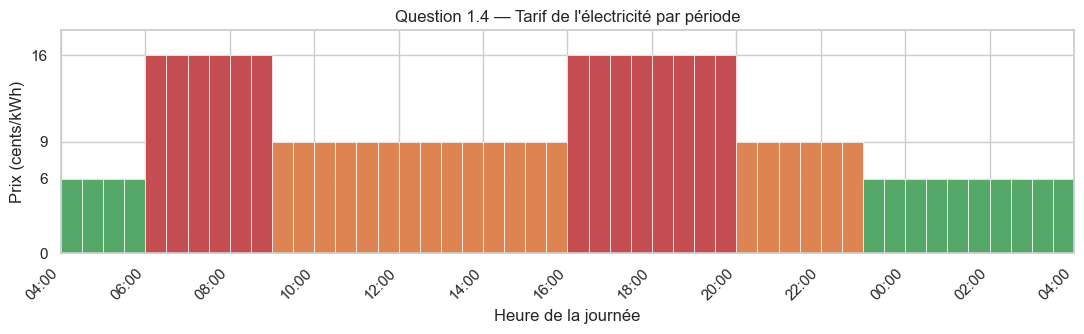

In [6]:
# Question 1.4 — Tarif de l'électricité par période
price = [6, 6, 6, 6, 16, 16, 16, 16, 16, 16, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 16, 16, 16, 16, 16, 16, 16, 16, 9, 9, 9, 9, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6]
heures_prix = [4.0 + 0.5 * (t - 1) for t in range(1, len(price) + 1)]
couleurs = {6: "C2", 9: "C1", 16: "C3"}

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(heures_prix, price, width=0.5, align="edge",
       color=[couleurs[p] for p in price], edgecolor="white", linewidth=0.5)

ticks = list(range(4, 29, 2))
ax.set_xticks(ticks)
ax.set_xticklabels([format_heure(h) for h in ticks], rotation=45, ha="right")
ax.set_xlim(4, 28)
ax.set_ylim(0, 18)
ax.set_yticks([0, 6, 9, 16])
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Prix (cents/kWh)")
ax.set_title("Question 1.4 — Tarif de l'électricité par période")

plt.tight_layout()
plt.savefig("Q1/1_4_tarifs.png", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
# Question 1.6 
puissance = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 150.0, 150.0, 150.0, 150.0, 208.125, 0.0, 300.0, 300.0, 0.0, 150.0, 150.0, 391.875, 30.0, 150.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875, 391.875]
grid_limit = 600.0

heures_p = [4.0 + 0.5 * (t - 1) for t in range(1, len(puissance) + 1)]

df_p = pd.DataFrame({
    "heure": heures_p,
    "puissance (kW)": puissance,
})

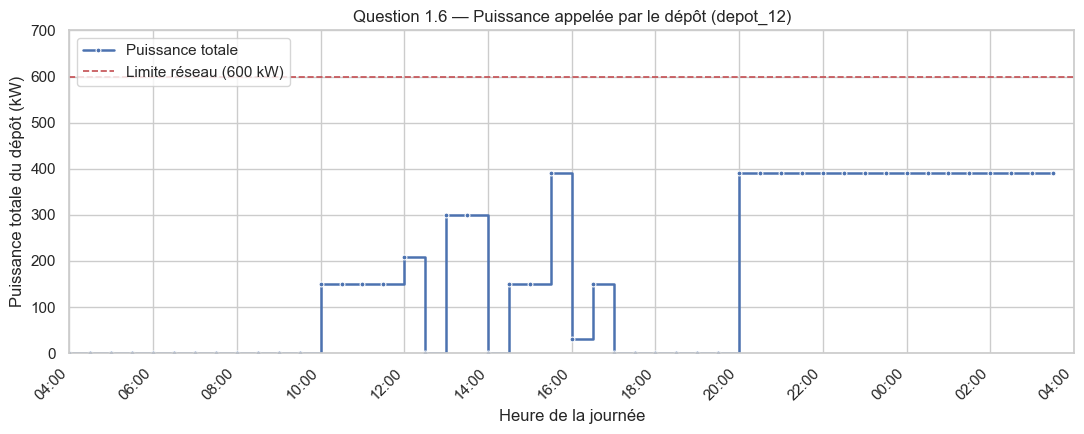

In [8]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 4.5))

sns.lineplot(
    data=df_p,
    x="heure",
    y="puissance (kW)",
    marker="o",
    markersize=3.5,
    linewidth=1.8,
    ax=ax,
    label="Puissance totale",
    drawstyle="steps-post",
)

ax.axhline(
    grid_limit,
    color="C3",
    linestyle="--",
    linewidth=1.2,
    label=f"Limite réseau ({grid_limit:.0f} kW)",
)

ticks = list(range(4, 29, 2))
ax.set_xticks(ticks)
ax.set_xticklabels([format_heure(h) for h in ticks], rotation=45, ha="right")
ax.set_xlim(4, 28)
ax.set_ylim(0, 700)

ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Puissance totale du dépôt (kW)")
ax.set_title("Question 1.6 — Puissance appelée par le dépôt (depot_12)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("Q1/1_6_puissance_depot.png", dpi=150, bbox_inches="tight")
plt.show()


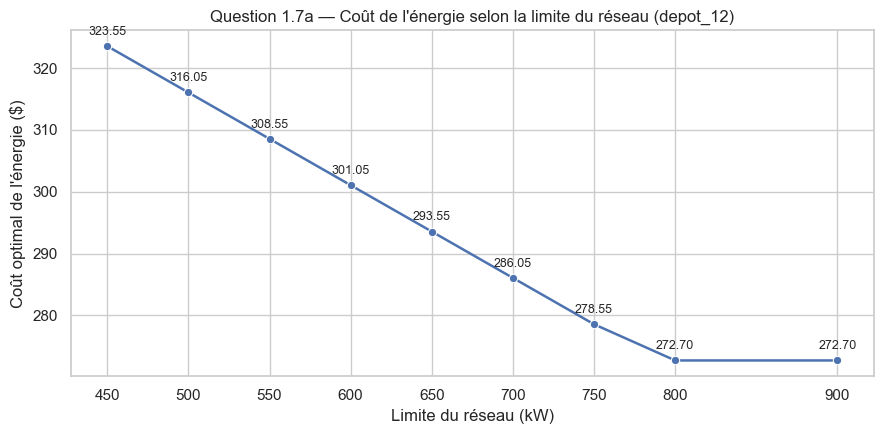

In [9]:
# Question 1.7a — Coût optimal de l'énergie en fonction de la limite du réseau (depot_12)
limites = [450, 500, 550, 600, 650, 700, 750, 800, 900]
cout_energie = [323.55, 316.05, 308.55, 301.05, 293.55, 286.05, 278.55, 272.70, 272.70]

df_q7 = pd.DataFrame({
    "limite (kW)": limites,
    "coût énergie ($)": cout_energie,
})

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.lineplot(
    data=df_q7,
    x="limite (kW)",
    y="coût énergie ($)",
    marker="o",
    markersize=6,
    linewidth=1.8,
    ax=ax,
)

for L, c in zip(limites, cout_energie):
    ax.annotate(f"{c:.2f}", (L, c), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)

ax.set_xticks(limites)
ax.set_xlabel("Limite du réseau (kW)")
ax.set_ylabel("Coût optimal de l'énergie ($)")
ax.set_title("Question 1.7a — Coût de l'énergie selon la limite du réseau (depot_12)")

plt.tight_layout()
plt.savefig("Q1/1_7a_cout_vs_limite.png", dpi=150, bbox_inches="tight")
plt.show()
